In [1]:
import os
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.model_selection import train_test_split
import torch.nn as nn
import torchvision.models as models
import torch.optim as optim
from tqdm import tqdm
from sklearn.metrics import roc_auc_score
import warnings
import matplotlib.pyplot as plt
import cv2
import random
import torch.nn.functional as F

In [2]:
# Initialize hardware
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Active Device: {device}")

Active Device: cuda


In [3]:
# Kaggle absolute paths
BASE_DIR = '/kaggle/input/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized'
IMAGE_DIR = f'{BASE_DIR}/images-224/images-224'
CSV_PATH = f'{BASE_DIR}/Data_Entry_2017.csv'

BATCH_SIZE = 32
IMAGE_SIZE = 224

DISEASE_LABELS = [
    'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration', 'Mass', 'Nodule', 
    'Pneumonia', 'Pneumothorax', 'Consolidation', 'Edema', 'Emphysema', 
    'Fibrosis', 'Pleural_Thickening', 'Hernia'
]

In [4]:
def process_metadata(csv_path, labels_list):
    df = pd.read_csv(csv_path)
    
    for label in labels_list:
        df[label] = df['Finding Labels'].apply(lambda x: 1.0 if label in str(x) else 0.0)
        
    return df

In [5]:
df_metadata = process_metadata(CSV_PATH, DISEASE_LABELS)
print(f"Dataset loaded with {len(df_metadata)} total records.")

Dataset loaded with 112120 total records.


In [6]:
class NIHChestXrayDataset(Dataset):
    def __init__(self, dataframe, image_dir, labels_list, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.labels_list = labels_list
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_name = self.dataframe.loc[idx, 'Image Index']
        img_path = os.path.join(self.image_dir, img_name)
        
        image = Image.open(img_path).convert('RGB')
        
        labels = self.dataframe.loc[idx, self.labels_list].values.astype(np.float32)
        labels_tensor = torch.tensor(labels)
        
        if self.transform:
            image = self.transform(image)
            
        return image, labels_tensor

In [7]:
# Training set:  data augmentation + normalization
train_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(degrees=10),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                         std=[0.229, 0.224, 0.225])  
])

# Validation set: only normalizion
val_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

print("Data transformations defined successfully.")

Data transformations defined successfully.


In [8]:
# Split the dataset (80/20)
train_df, val_df = train_test_split(df_metadata, test_size=0.2, random_state=42)

# Reset index
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

# custom datasets
train_dataset = NIHChestXrayDataset(train_df, IMAGE_DIR, DISEASE_LABELS, transform=train_transforms)
val_dataset = NIHChestXrayDataset(val_df, IMAGE_DIR, DISEASE_LABELS, transform=val_transforms)

# Create the DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

Training batches: 2803
Validation batches: 701


In [9]:
def build_densenet121(num_classes):
    model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
    
    # Extract the number of input features going into the final layer
    in_features = model.classifier.in_features
    
    # Replace the final layer with a new one mapped to our 14 target classes
    model.classifier = nn.Linear(in_features, num_classes)
    
    return model

In [10]:
model = build_densenet121(num_classes=len(DISEASE_LABELS))
model = model.to(device)

print(f"Model successfully loaded and moved to {device}")

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 126MB/s]


Model successfully loaded and moved to cuda


In [11]:
criterion = nn.BCEWithLogitsLoss()

# conservative learning rate
learning_rate = 1e-4
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

print("Loss function and optimizer initialized.")

Loss function and optimizer initialized.


In [12]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    
    progress_bar = tqdm(dataloader, desc="Training", leave=False)
    
    for images, labels in progress_bar:
        # Moving data to the GPU
        images = images.to(device)
        labels = labels.to(device)
        
        # Clearing out gradients
        optimizer.zero_grad()
        
        # Forward pass
        outputs = model(images)
        
        # Calculate loss
        loss = criterion(outputs, labels)
        
        # Backward pass
        loss.backward()
        
        # updation of weights
        optimizer.step()
        
        running_loss += loss.item()
        progress_bar.set_postfix({'loss': f'{loss.item():.4f}'})
        
    return running_loss / len(dataloader)

In [13]:
def validate(model, dataloader, criterion, device):
    model.eval()
    val_loss = 0.0
    
    all_targets = []
    all_predictions = []
    
    with torch.no_grad():
        progress_bar = tqdm(dataloader, desc="Validating", leave=False)
        for images, labels in progress_bar:
            images = images.to(device)
            labels = labels.to(device)
            
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            
            probs = torch.sigmoid(outputs)
            
            # Store targets and predictions to calculate AUC
            all_targets.append(labels.cpu().numpy())
            all_predictions.append(probs.cpu().numpy())
            
    # Concatenate all batches into single arrays
    all_targets = np.vstack(all_targets)
    all_predictions = np.vstack(all_predictions)
    
    # Calculate ROC-AUC score
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            # average='macro' calculates the metric independently for each disease and averages them
            auc_score = roc_auc_score(all_targets, all_predictions, average='macro')
        except ValueError:
            auc_score = 0.0 # Fallback if there's an issue with class distribution in a small sample
            
    return val_loss / len(dataloader), auc_score

In [14]:
EPOCHS = 3
best_val_loss = float('inf')
SAVE_PATH = '/kaggle/working/best_densenet121.pth'

print(f"Starting training loop for {EPOCHS} epochs...")

for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    
    # 1. Train the model 
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    
    # 2. Validate the model on unseen data
    val_loss, val_auc = validate(model, val_loader, criterion, device)
    
    # 3. Print the performance metrics
    print(f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Macro AUC: {val_auc:.4f}")
    
    # 4. Checkpoint Logic (Save if it's the best so far)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), SAVE_PATH)
        print(f"[*] Validation loss decreased. Saved best model to {SAVE_PATH}")

print(f"\nTraining complete! Your baseline DenseNet-121 model is saved at: {SAVE_PATH}")

Starting training loop for 3 epochs...

Epoch 1/3


Train Loss: 0.1629 | Val Loss: 0.1491 | Val Macro AUC: 0.8119
[*] Validation loss decreased. Saved best model to /kaggle/working/best_densenet121.pth

Epoch 2/3


Train Loss: 0.1490 | Val Loss: 0.1456 | Val Macro AUC: 0.8286
[*] Validation loss decreased. Saved best model to /kaggle/working/best_densenet121.pth

Epoch 3/3


Train Loss: 0.1453 | Val Loss: 0.1442 | Val Macro AUC: 0.8374
[*] Validation loss decreased. Saved best model to /kaggle/working/best_densenet121.pth

Training complete! Your baseline DenseNet-121 model is saved at: /kaggle/working/best_densenet121.pth


In [15]:
def build_efficientnet(num_classes):
    # Load the pretrained EfficientNet-B0
    model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    
    # EfficientNet's final classification layer is inside a Sequential block called 'classifier'
    # The actual Linear layer is at index 1. We replace it to map to our 14 target diseases.
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    
    return model

In [16]:
effnet_model = build_efficientnet(num_classes=len(DISEASE_LABELS))
effnet_model = effnet_model.to(device)

effnet_optimizer = optim.Adam(effnet_model.parameters(), lr=1e-4)

print(f"Model 2: EfficientNet-B0 successfully loaded and moved to {device}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 141MB/s] 


Model 2: EfficientNet-B0 successfully loaded and moved to cuda


In [17]:
EPOCHS = 3
best_val_loss_eff = float('inf')
SAVE_PATH_EFF = '/kaggle/working/best_efficientnet.pth'

print(f"Starting EfficientNet-B0 training loop for {EPOCHS} epochs...")

for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch+1}/{EPOCHS} (EfficientNet-B0)")
    
    # 1. Train
    train_loss = train_one_epoch(effnet_model, train_loader, criterion, effnet_optimizer, device)
    
    # 2. Validate
    val_loss, val_auc = validate(effnet_model, val_loader, criterion, device)
    
    # 3. Print metrics
    print(f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Macro AUC: {val_auc:.4f}")
    
    # 4. Checkpoint Logic
    if val_loss < best_val_loss_eff:
        best_val_loss_eff = val_loss
        torch.save(effnet_model.state_dict(), SAVE_PATH_EFF)
        print(f"[*] Validation loss decreased. Saved best EfficientNet model to {SAVE_PATH_EFF}")

print(f"\nEfficientNet Training complete! Weights saved at: {SAVE_PATH_EFF}")

Starting EfficientNet-B0 training loop for 3 epochs...

Epoch 1/3 (EfficientNet-B0)


Train Loss: 0.1686 | Val Loss: 0.1509 | Val Macro AUC: 0.8005
[*] Validation loss decreased. Saved best EfficientNet model to /kaggle/working/best_efficientnet.pth

Epoch 2/3 (EfficientNet-B0)


Train Loss: 0.1514 | Val Loss: 0.1474 | Val Macro AUC: 0.8189
[*] Validation loss decreased. Saved best EfficientNet model to /kaggle/working/best_efficientnet.pth

Epoch 3/3 (EfficientNet-B0)


Train Loss: 0.1473 | Val Loss: 0.1454 | Val Macro AUC: 0.8289
[*] Validation loss decreased. Saved best EfficientNet model to /kaggle/working/best_efficientnet.pth

EfficientNet Training complete! Weights saved at: /kaggle/working/best_efficientnet.pth


In [18]:
class HybridCvT(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        resnet = models.resnet34(weights=models.ResNet34_Weights.IMAGENET1K_V1)
        self.backbone = nn.Sequential(*list(resnet.children())[:-2])
        
        # 2. Transformer Encoder: Treats the 7x7 spatial grid as 49 distinct "patches"
        encoder_layer = nn.TransformerEncoderLayer(d_model=512, nhead=8, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=2)
        
        # 3. Final Classification Head
        self.classifier = nn.Linear(512, num_classes)
        
    def forward(self, x):
        # Extract features using the CNN
        features = self.backbone(x)
        batch_size, channels, h, w = features.shape
        
        # Flatten spatial dimensions to create sequence of patches: [batch, 49 patches, 512 channels]
        patches = features.view(batch_size, channels, -1).permute(0, 2, 1)
        
        # Apply Transformer Attention over the patches
        transformer_out = self.transformer(patches)
        
        # Average the sequence to get a single vector per image, then classify
        pooled = transformer_out.mean(dim=1)
        return self.classifier(pooled)

In [19]:
cvt_model = HybridCvT(num_classes=len(DISEASE_LABELS))
cvt_model = cvt_model.to(device)

# Initialize optimizer for CvT
cvt_optimizer = optim.Adam(cvt_model.parameters(), lr=1e-4)

print(f"Model 3: Hybrid CNN-Transformer successfully built and moved to {device}")

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 182MB/s]


Model 3: Hybrid CNN-Transformer successfully built and moved to cuda


In [20]:
EPOCHS = 3
best_val_loss_cvt = float('inf')
SAVE_PATH_CVT = '/kaggle/working/best_cvt.pth'

print(f"Starting Hybrid CvT training loop for {EPOCHS} epochs...")

for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch+1}/{EPOCHS} (Hybrid CvT)")
    
    # 1. Train
    train_loss = train_one_epoch(cvt_model, train_loader, criterion, cvt_optimizer, device)
    
    # 2. Validate
    val_loss, val_auc = validate(cvt_model, val_loader, criterion, device)
    
    # 3. Print metrics
    print(f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Macro AUC: {val_auc:.4f}")
    
    # 4. Checkpoint Logic
    if val_loss < best_val_loss_cvt:
        best_val_loss_cvt = val_loss
        torch.save(cvt_model.state_dict(), SAVE_PATH_CVT)
        print(f"[*] Validation loss decreased. Saved best Hybrid model to {SAVE_PATH_CVT}")

print(f"\nHybrid Training complete! Weights saved at: {SAVE_PATH_CVT}")

Starting Hybrid CvT training loop for 3 epochs...

Epoch 1/3 (Hybrid CvT)


Train Loss: 0.1619 | Val Loss: 0.1520 | Val Macro AUC: 0.7985
[*] Validation loss decreased. Saved best Hybrid model to /kaggle/working/best_cvt.pth

Epoch 2/3 (Hybrid CvT)


Train Loss: 0.1525 | Val Loss: 0.1494 | Val Macro AUC: 0.8131
[*] Validation loss decreased. Saved best Hybrid model to /kaggle/working/best_cvt.pth

Epoch 3/3 (Hybrid CvT)


Train Loss: 0.1488 | Val Loss: 0.1491 | Val Macro AUC: 0.8190
[*] Validation loss decreased. Saved best Hybrid model to /kaggle/working/best_cvt.pth

Hybrid Training complete! Weights saved at: /kaggle/working/best_cvt.pth


In [21]:
def evaluate_saved_model_accuracy(model, model_path, dataloader, device):
    """Loads a saved model and calculates its strict multi-label accuracy."""
    # 1. Load the saved weights into the model
    model.load_state_dict(torch.load(model_path))
    model.eval()
    
    correct_predictions = 0
    total_predictions = 0
    
    print(f"Calculating accuracy for: {model_path}...")
    
    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)
            
            # Get raw outputs and convert to percentages
            outputs = model(images)
            probs = torch.sigmoid(outputs)
            
            # Thresholding: If confidence is > 50%, predict 1.0 (Disease Present), else 0.0
            predictions = (probs > 0.5).float()
            
            # Count how many of the 14 labels exactly matched the actual patient data
            correct_predictions += (predictions == labels).sum().item()
            
            # Total predictions is batch_size * 14 diseases
            total_predictions += labels.numel()
            
    accuracy = (correct_predictions / total_predictions) * 100
    print(f"Final Validation Accuracy: {accuracy:.2f}%")
    return accuracy

# 1. Evaluate the DenseNet-121 Baseline
print("\n--- DenseNet-121 ---")
densenet_acc = evaluate_saved_model_accuracy(model, '/kaggle/working/best_densenet121.pth', val_loader, device)

# 2. Evaluate the Vision Transformer (Uncomment if ViT is fully trained)
print("\n--- EfficientNet-B0 ---")
effnet_acc = evaluate_saved_model_accuracy(effnet_model, '/kaggle/working/best_efficientnet.pth', val_loader, device)

# 3. Evaluate the Hybrid CvT (Uncomment if Hybrid CvT is fully trained)
print("\n--- Hybrid CNN-Transformer (CvT) ---")
cvt_acc = evaluate_saved_model_accuracy(cvt_model, '/kaggle/working/best_cvt.pth', val_loader, device)


--- DenseNet-121 ---
Calculating accuracy for: /kaggle/working/best_densenet121.pth...
Final Validation Accuracy: 95.05%

--- EfficientNet-B0 ---
Calculating accuracy for: /kaggle/working/best_efficientnet.pth...
Final Validation Accuracy: 95.06%

--- Hybrid CNN-Transformer (CvT) ---
Calculating accuracy for: /kaggle/working/best_cvt.pth...
Final Validation Accuracy: 94.88%


In [22]:
def predict_single_image(image_path, model, transform, device, labels_list):
    """Loads an X-ray, makes a prediction, and returns sorted probabilities."""
    # 1. Load and format the raw image
    raw_image = Image.open(image_path).convert('RGB')
    
    # 2. Apply the strict validation transforms (no random rotations here)
    input_tensor = transform(raw_image).unsqueeze(0).to(device)
    
    # 3. Make the prediction
    model.eval()
    with torch.no_grad():
        outputs = model(input_tensor)
        # Apply sigmoid to convert raw model outputs to percentages (0.0 to 1.0)
        probabilities = torch.sigmoid(outputs)[0].cpu().numpy()
        
    # 4. Mapping the mathematical probabilities to the actual disease names
    results = {labels_list[i]: float(probabilities[i]) for i in range(len(labels_list))}
    
    # Sort from highest confidence to lowest
    sorted_results = dict(sorted(results.items(), key=lambda item: item[1], reverse=True))
    
    return sorted_results, input_tensor, raw_image

print("Universal inference function ready.")

Universal inference function ready.


In [23]:
class DenseNetGradCAM:
    """Generates a mathematical heatmap showing what the DenseNet model is looking at."""
    def __init__(self, model):
        self.model = model
        self.gradients = None
        self.activations = None
        
        # DenseNet121's final convolutional block is named 'features'
        self.target_layer = self.model.features
        
        # Attach the hooks to intercept the data
        self.target_layer.register_forward_hook(self.hook_activations)
        self.target_layer.register_full_backward_hook(self.hook_gradients)
        
    def hook_activations(self, module, input, output):
        self.activations = output
        
    def hook_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]
        
    def generate_heatmap(self, input_tensor, target_class_index):
        # 1. Clear old gradients
        self.model.zero_grad()
        
        # 2. Forward pass
        output = self.model(input_tensor)
        
        # 3. Target the specific disease we want to visualize and trigger backward pass
        target = output[0, target_class_index]
        target.backward() 
        
        # 4. Pool the gradients and multiply by the activations
        pooled_gradients = torch.mean(self.gradients, dim=[0, 2, 3])
        activations = self.activations.detach()[0]
        
        for i in range(activations.size(0)):
            activations[i, :, :] *= pooled_gradients[i]
            
        # 5. Compress into a single 2D heatmap
        heatmap = torch.mean(activations, dim=0).squeeze().cpu().numpy()
        
        # 6. Apply ReLU (we only want the pixels that had a *positive* impact on the prediction)
        heatmap = np.maximum(heatmap, 0)
        
        # 7. Normalize the heatmap values between 0 and 1
        heatmap /= np.max(heatmap) + 1e-8
        
        return heatmap

print("Grad-CAM Engine compiled.")

Grad-CAM Engine compiled.


In [24]:
def visualize_gradcam(original_image, heatmap, disease_name, confidence):
    """Blends the Grad-CAM heatmap over the original X-ray for clinical review."""
    # Resize the heatmap to match the original image dimensions
    heatmap_resized = cv2.resize(heatmap, (original_image.size[0], original_image.size[1]))
    
    # Convert to 8-bit image and apply the medical JET color map
    heatmap_8bit = np.uint8(255 * heatmap_resized)
    heatmap_color = cv2.applyColorMap(heatmap_8bit, cv2.COLORMAP_JET)
    
    # Convert original PIL image to OpenCV BGR format
    original_cv2 = cv2.cvtColor(np.array(original_image), cv2.COLOR_RGB2BGR)
    
    # Blend them together (0.6 opacity for the X-ray, 0.4 for the heatmap)
    superimposed_img = cv2.addWeighted(original_cv2, 0.6, heatmap_color, 0.4, 0)
    
    # Plot side-by-side using matplotlib
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    
    ax[0].imshow(original_image)
    ax[0].set_title("Original Chest X-Ray", fontsize=14)
    ax[0].axis('off')
    
    # Convert BGR back to RGB for proper matplotlib rendering
    superimposed_img_rgb = cv2.cvtColor(superimposed_img, cv2.COLOR_BGR2RGB)
    ax[1].imshow(superimposed_img_rgb)
    ax[1].set_title(f"AI Focus: {disease_name} ({confidence*100:.1f}% Confidence)", fontsize=14)
    ax[1].axis('off')
    
    plt.tight_layout()
    plt.show()

print("Visualization tools ready.")

Visualization tools ready.


Testing X-Ray File: 00020364_000.png
------------------------------
Diagnostic Predictions:
 > Infiltration: 10.80%
 > Atelectasis: 1.23%
 > Mass: 0.85%


sys:1: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


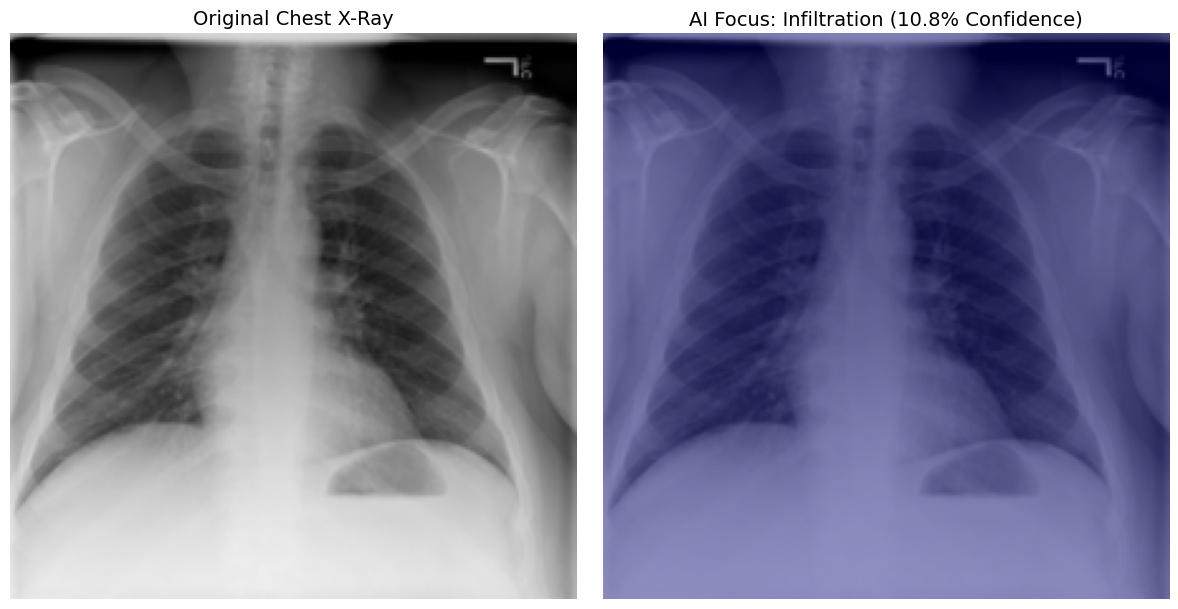

In [25]:
def patched_forward(x):
    features = model.features(x)
    out = F.relu(features, inplace=False) 
    out = F.adaptive_avg_pool2d(out, (1, 1))
    out = torch.flatten(out, 1)
    out = model.classifier(out)
    return out

model.forward = patched_forward

# 2. Pick a random test image from the validation dataframe
random_index = random.randint(0, len(val_df) - 1)
test_image_filename = val_df.iloc[random_index]['Image Index']
test_image_path = os.path.join(IMAGE_DIR, test_image_filename)

print(f"Testing X-Ray File: {test_image_filename}")
print("-" * 30)

# 3. Run the Inference Function
predictions, input_tensor, raw_image = predict_single_image(
    test_image_path, model, val_transforms, device, DISEASE_LABELS
)

# 4. Print the Top 3 Predictions
print("Diagnostic Predictions:")
top_3 = list(predictions.items())[:3]
for disease, prob in top_3:
    print(f" > {disease}: {prob*100:.2f}%")

# 5. Generate and Display the Grad-CAM for the highest confidence disease
top_disease_name = top_3[0][0]
top_disease_index = DISEASE_LABELS.index(top_disease_name)
top_confidence = top_3[0][1]

cam_engine = DenseNetGradCAM(model)
heatmap = cam_engine.generate_heatmap(input_tensor, top_disease_index)

# Render the final output
visualize_gradcam(raw_image, heatmap, top_disease_name, top_confidence)

In [26]:
class EfficientNetGradCAM:
    """Generates a Grad-CAM heatmap specifically for EfficientNet-B0."""
    def __init__(self, model):
        self.model = model
        self.gradients = None
        self.activations = None
        
        # EfficientNet-B0's final convolutional block is 'features[-1]'
        self.target_layer = self.model.features[-1]
        
        self.target_layer.register_forward_hook(self.hook_activations)
        self.target_layer.register_full_backward_hook(self.hook_gradients)
        
    def hook_activations(self, module, input, output):
        self.activations = output
        
    def hook_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]
        
    def generate_heatmap(self, input_tensor, target_class_index):
        self.model.zero_grad()
        output = self.model(input_tensor)
        target = output[0, target_class_index]
        target.backward() 
        
        pooled_gradients = torch.mean(self.gradients, dim=[0, 2, 3])
        activations = self.activations.detach()[0]
        
        for i in range(activations.size(0)):
            activations[i, :, :] *= pooled_gradients[i]
            
        heatmap = torch.mean(activations, dim=0).squeeze().cpu().numpy()
        heatmap = np.maximum(heatmap, 0)
        heatmap /= np.max(heatmap) + 1e-8
        
        return heatmap

Testing X-Ray File: 00020364_000.png (EfficientNet-B0)
------------------------------
Diagnostic Predictions:
 > Infiltration: 11.28%
 > Nodule: 3.01%
 > Atelectasis: 1.66%


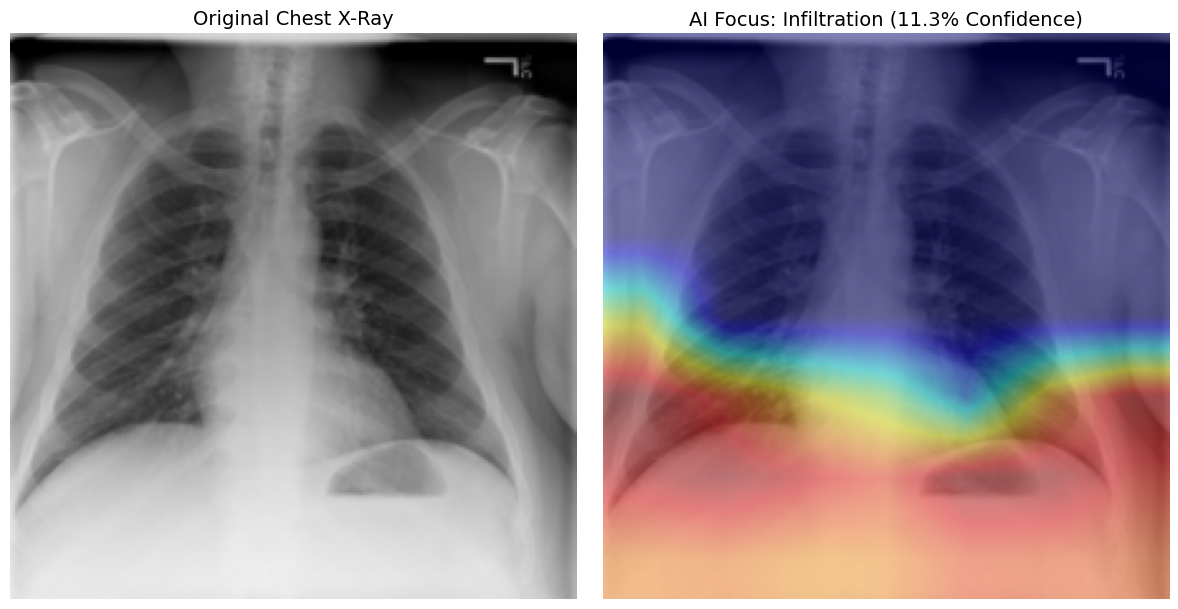

In [27]:
# 1. Load the best EfficientNet weights
effnet_model.load_state_dict(torch.load('/kaggle/working/best_efficientnet.pth'))
effnet_model.eval()

# 2. Pick a random test image (you can use the same random_index to compare the exact same image!)
print(f"Testing X-Ray File: {test_image_filename} (EfficientNet-B0)")
print("-" * 30)

# 3. Run Inference using effnet_model
predictions, input_tensor, raw_image = predict_single_image(
    test_image_path, effnet_model, val_transforms, device, DISEASE_LABELS
)

# 4. Print Predictions
print("Diagnostic Predictions:")
top_3 = list(predictions.items())[:3]
for disease, prob in top_3:
    print(f" > {disease}: {prob*100:.2f}%")

# 5. Generate Heatmap using the NEW EfficientNet Grad-CAM Engine
top_disease_name = top_3[0][0]
top_disease_index = DISEASE_LABELS.index(top_disease_name)
top_confidence = top_3[0][1]

cam_engine_eff = EfficientNetGradCAM(effnet_model)
heatmap = cam_engine_eff.generate_heatmap(input_tensor, top_disease_index)

# Render the final output
visualize_gradcam(raw_image, heatmap, top_disease_name, top_confidence)

In [28]:
class HybridCvTGradCAM:
    """Generates a Grad-CAM heatmap specifically for the Hybrid CNN-Transformer."""
    def __init__(self, model):
        self.model = model
        self.gradients = None
        self.activations = None
        
        # We hook into the final layer of the CNN backbone BEFORE it hits the Transformer
        # This gives us the best spatial map of what the model is focusing on
        self.target_layer = self.model.backbone[-1]
        
        self.target_layer.register_forward_hook(self.hook_activations)
        self.target_layer.register_full_backward_hook(self.hook_gradients)
        
    def hook_activations(self, module, input, output):
        self.activations = output
        
    def hook_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]
        
    def generate_heatmap(self, input_tensor, target_class_index):
        self.model.zero_grad()
        output = self.model(input_tensor)
        target = output[0, target_class_index]
        target.backward() 
        
        pooled_gradients = torch.mean(self.gradients, dim=[0, 2, 3])
        activations = self.activations.detach()[0]
        
        for i in range(activations.size(0)):
            activations[i, :, :] *= pooled_gradients[i]
            
        heatmap = torch.mean(activations, dim=0).squeeze().cpu().numpy()
        heatmap = np.maximum(heatmap, 0)
        heatmap /= np.max(heatmap) + 1e-8
        
        return heatmap

Testing X-Ray File: 00020364_000.png (Hybrid CvT)
------------------------------
Diagnostic Predictions:
 > Infiltration: 9.79%
 > Atelectasis: 1.31%
 > Cardiomegaly: 1.29%


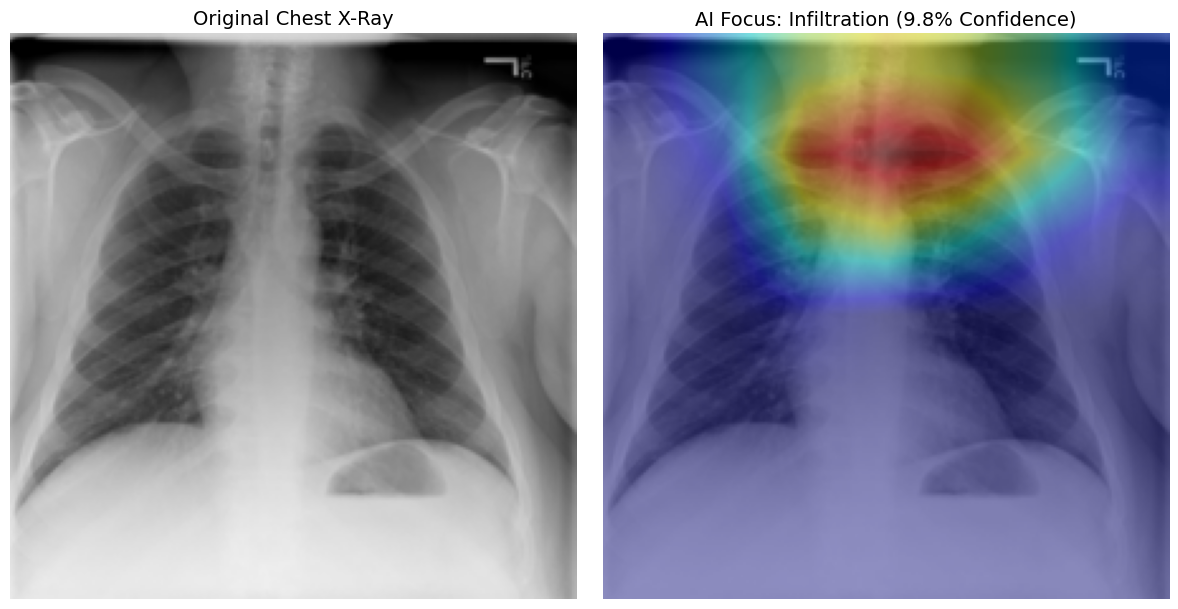

In [29]:
# 1. Load the best Hybrid weights
cvt_model.load_state_dict(torch.load('/kaggle/working/best_cvt.pth'))
cvt_model.eval()

# 2. Use the exact same test image so you can compare the models side-by-side in your paper
print(f"Testing X-Ray File: {test_image_filename} (Hybrid CvT)")
print("-" * 30)

# 3. Run Inference using cvt_model
predictions, input_tensor, raw_image = predict_single_image(
    test_image_path, cvt_model, val_transforms, device, DISEASE_LABELS
)

# 4. Print Predictions
print("Diagnostic Predictions:")
top_3 = list(predictions.items())[:3]
for disease, prob in top_3:
    print(f" > {disease}: {prob*100:.2f}%")

# 5. Generate Heatmap
top_disease_name = top_3[0][0]
top_disease_index = DISEASE_LABELS.index(top_disease_name)
top_confidence = top_3[0][1]

cam_engine_cvt = HybridCvTGradCAM(cvt_model)
heatmap = cam_engine_cvt.generate_heatmap(input_tensor, top_disease_index)

# Render the final output
visualize_gradcam(raw_image, heatmap, top_disease_name, top_confidence)